In [1]:
import xarray as xr 
import pandas as pd
import matplotlib.pyplot as plt
from oceanum.datamesh import Connector

datamesh = Connector()

In [2]:
ds = xr.open_dataset("/home/nn411/Projects/OceanAtm/Moana-2.0/Data/atm_ifs_raw_2026-01-01_90D.nc")

print(ds.sizes["time"])                                                     # 724
print(ds.time.values[0], "->", ds.time.values[-1])                          # Dec 31 15Z -> Apr 1 00Z
print("gaps:", (ds.time.diff("time") != pd.Timedelta("3h")).sum().values)   # 0
print(float(ds.longitude.min()), "->", float(ds.longitude.max()))           # ~160.75 -> ~185.25
print(list(ds.data_vars))                                                   # all 8
print("NaNs:", {v: int(ds[v].isnull().sum()) for v in ds.data_vars})       # all 0

724
2025-12-31T15:00:00.000000000 -> 2026-04-01T00:00:00.000000000
gaps: 0
160.75 -> 185.25
['u10', 'v10', 't2m', 'd2m', 'msl', 'tp', 'ssr', 'strd']
NaNs: {'u10': 0, 'v10': 0, 't2m': 0, 'd2m': 0, 'msl': 0, 'tp': 0, 'ssr': 0, 'strd': 0}


In [3]:
print(ds)

<xarray.Dataset> Size: 200MB
Dimensions:    (time: 724, latitude: 87, longitude: 99)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2025-12-31T15:00:00 ... 2026-04-01
  * latitude   (latitude) float32 348B -52.25 -52.0 -51.75 ... -31.0 -30.75
  * longitude  (longitude) float32 396B 160.8 161.0 161.2 ... 184.8 185.0 185.2
Data variables:
    u10        (time, latitude, longitude) float32 25MB -1.575 -2.028 ... 0.5771
    v10        (time, latitude, longitude) float32 25MB -1.627 -1.627 ... 2.808
    t2m        (time, latitude, longitude) float32 25MB 281.8 282.0 ... 295.3
    d2m        (time, latitude, longitude) float32 25MB 280.6 280.5 ... 291.6
    msl        (time, latitude, longitude) float32 25MB 1.004e+05 ... 1.015e+05
    tp         (time, latitude, longitude) float32 25MB 1.766e-10 ... 3.885e-09
    ssr        (time, latitude, longitude) float32 25MB 1.192e-05 ... 627.7
    strd       (time, latitude, longitude) float32 25MB 324.4 333.3 ... 381.2
Attributes:
    title: 

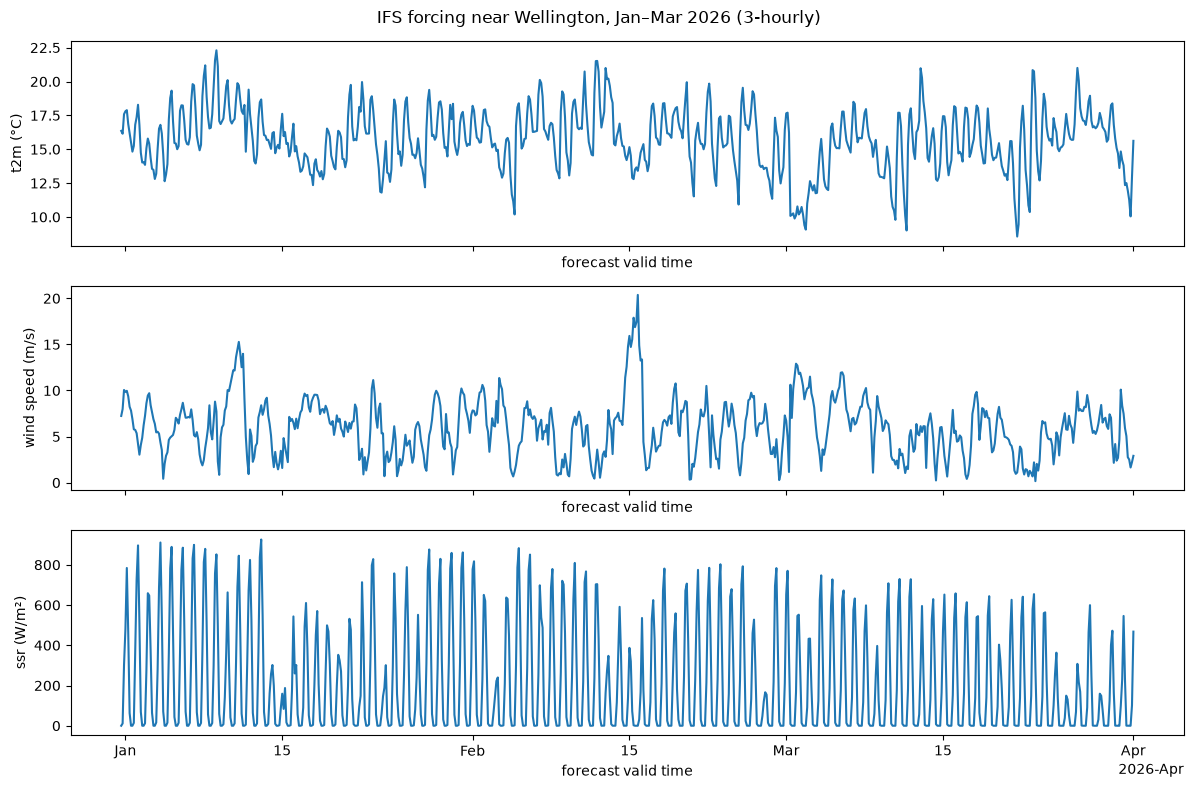

In [8]:
pt = ds.sel(longitude=174.78, latitude=-41.28, method="nearest")   # near Wellington

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
(pt.t2m - 273.15).plot(ax=axes[0]);  axes[0].set_ylabel("t2m (°C)")
((pt.u10**2 + pt.v10**2) ** 0.5).plot(ax=axes[1]);  axes[1].set_ylabel("wind speed (m/s)")
pt.ssr.plot(ax=axes[2]);  axes[2].set_ylabel("ssr (W/m²)")
for ax in axes: ax.set_title("")
fig.suptitle("IFS forcing near Wellington, Jan–Mar 2026 (3-hourly)")
plt.tight_layout()

Text(0.5, 1.0, '2 m temperature, 2026-01-13 03:00 UTC')

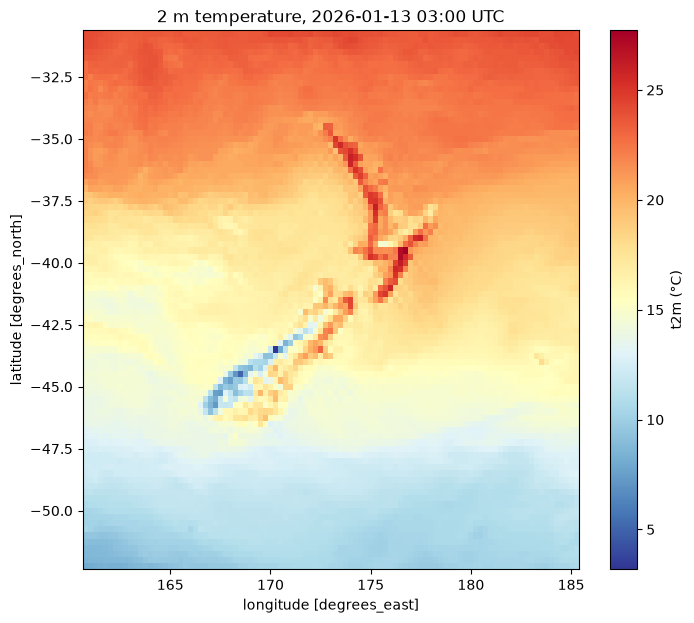

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
(ds.t2m.isel(time=100) - 273.15).plot(ax=ax, cmap="RdYlBu_r", cbar_kwargs={"label": "t2m (°C)"})
ax.set_title(f"2 m temperature, {pd.Timestamp(ds.time.values[100]):%Y-%m-%d %H:%M} UTC")

In [10]:
print(ds.time.diff("time").to_series().value_counts())

time
0 days 03:00:00    723
Name: count, dtype: int64


In [11]:
summary = pd.DataFrame({
    v: {"units": ds[v].attrs.get("units", ""),
        "min": float(ds[v].min()), "mean": float(ds[v].mean()), "max": float(ds[v].max())}
    for v in ds.data_vars
}).T
print(summary)

        units         min           mean          max
u10   m s**-1  -26.261078       1.378655      31.5009
v10   m s**-1  -26.399246       0.403424    30.751663
t2m         K   267.75531     289.539398   307.675598
d2m         K  254.312576     285.613373   297.783813
msl        Pa    96485.75  101271.054688  104189.3125
tp    m s**-1         0.0            0.0     0.000013
ssr   W m**-2         0.0     211.613632  1031.514038
strd  W m**-2  209.563354     346.039825   444.909088


Text(0.5, 1.0, '4 days near Wellington; dashed = cycle joins (00Z/12Z)')

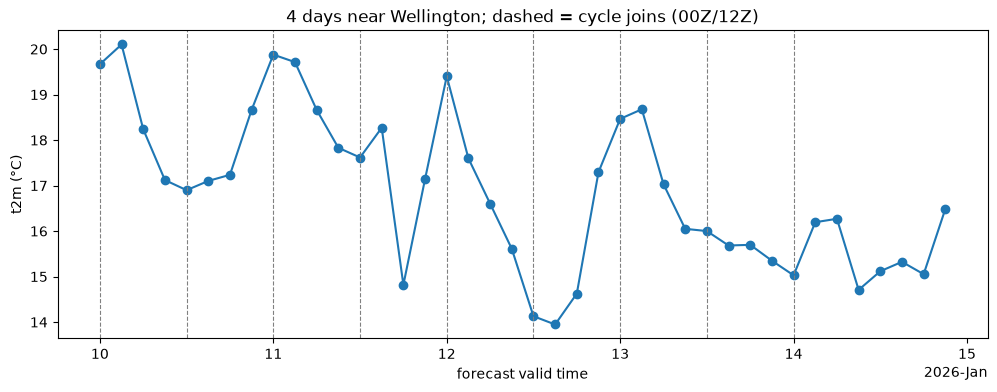

In [12]:
pt = ds.sel(longitude=174.78, latitude=-41.28, method="nearest")
week = pt.sel(time=slice("2026-01-10", "2026-01-14"))

fig, ax = plt.subplots(figsize=(12, 4))
(week.t2m - 273.15).plot(ax=ax, marker="o")
for t in pd.date_range("2026-01-10", "2026-01-14", freq="12h"):
    ax.axvline(t, color="grey", ls="--", lw=0.8)      # cycle boundaries
ax.set_ylabel("t2m (°C)"); ax.set_title("4 days near Wellington; dashed = cycle joins (00Z/12Z)")

Text(0.5, 1.0, 'Chained short forecasts vs one long forecast')

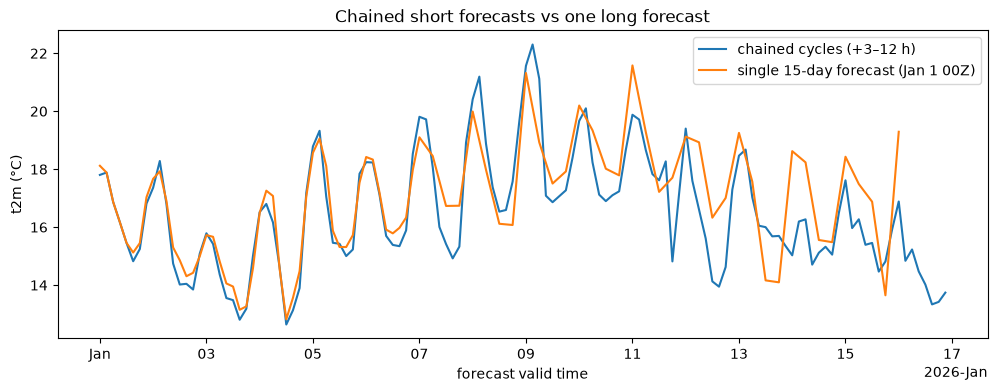

In [14]:
long = datamesh.query(
    datasource="ecmwf_ifs_0p25_oper_sfc", variables=["t2m"],
    parameters={"cycle": "2026010100"},
    timefilter={"type": "range", "times": ["2026-01-01", "2026-01-16"]},
    geofilter={"type": "bbox", "geom": [174.5, -41.5, 175.0, -41.0]},
).sel(longitude=174.78, latitude=-41.28, method="nearest")

fig, ax = plt.subplots(figsize=(12, 4))
(pt.t2m.sel(time=slice("2026-01-01", "2026-01-16")) - 273.15).plot(ax=ax, label="chained cycles (+3–12 h)")
(long.t2m - 273.15).plot(ax=ax, label="single 15-day forecast (Jan 1 00Z)")
ax.legend(); ax.set_ylabel("t2m (°C)"); ax.set_title("Chained short forecasts vs one long forecast")

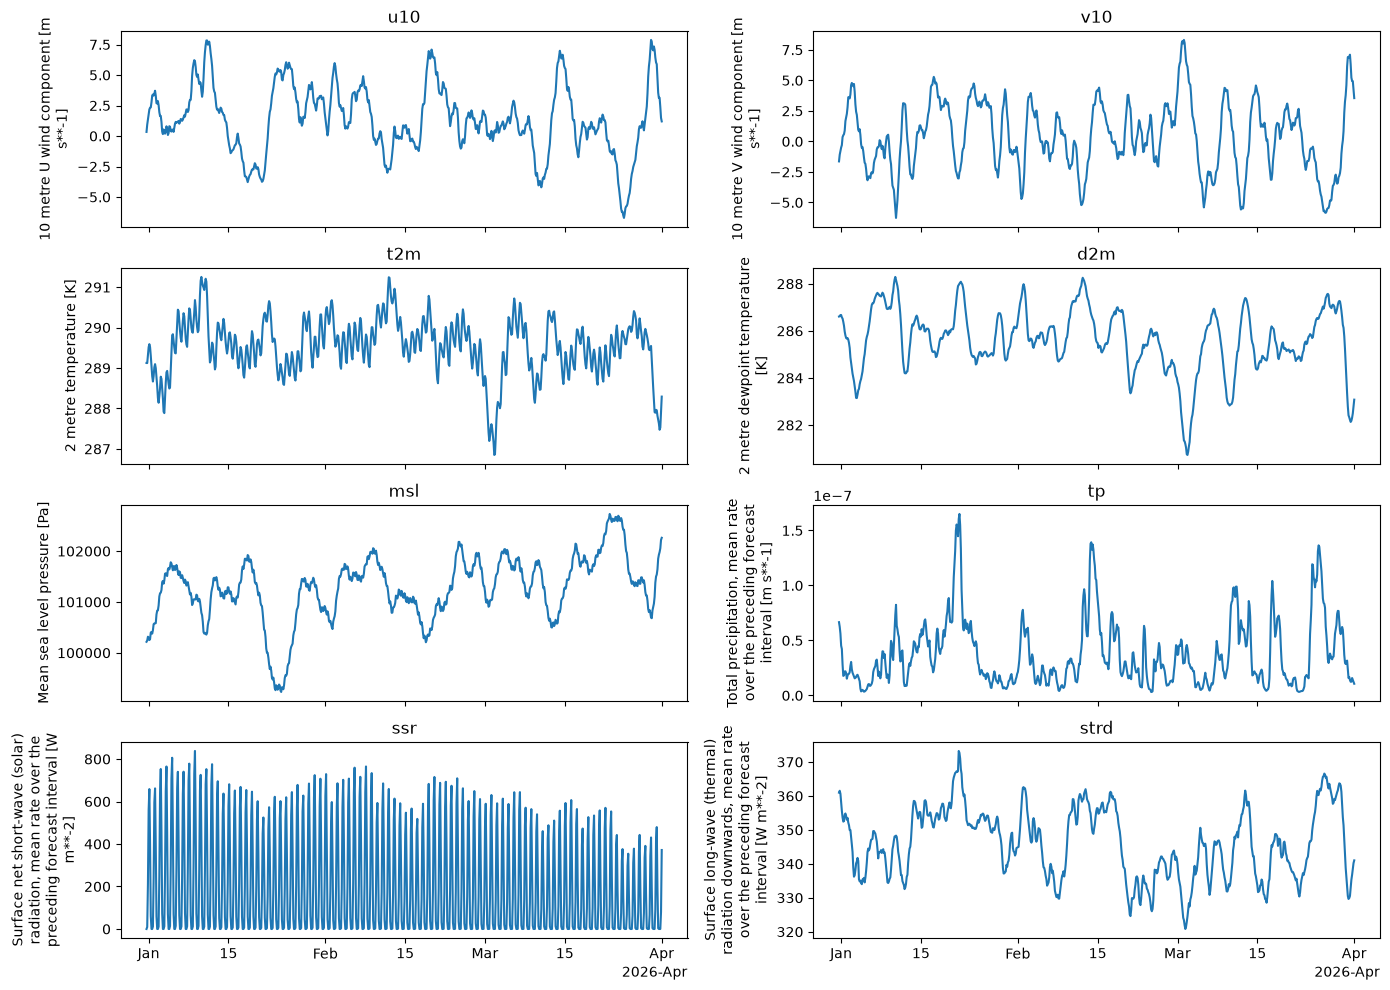

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
for ax, v in zip(axes.flat, ds.data_vars):
    ds[v].mean(["latitude", "longitude"]).plot(ax=ax)
    ax.set_title(v); ax.set_xlabel("")
plt.tight_layout()

In [4]:
import numpy as np
import xarray as xr

ds = xr.open_dataset("/home/nn411/Projects/OceanAtm/Moana-2.0/Data/atm_ifs_raw_2026-01-01_90D.nc")
print(ds, "\n")

lon = ds["longitude"] if "longitude" in ds else ds["lon"]
lat = ds["latitude"] if "latitude" in ds else ds["lat"]
print(f"lon: {float(lon.min())} to {float(lon.max())}  ({lon.size} pts)")
print(f"lat: {float(lat.min())} to {float(lat.max())}  ({lat.size} pts)\n")

t = ds["time"].values
print(f"time: {t[0]}  ->  {t[-1]}   ({len(t)} records)")
dt = np.diff(t).astype("timedelta64[m]").astype(int) / 60
steps, counts = np.unique(dt, return_counts=True)
print("time steps (h):", dict(zip(steps, counts)))
for i in np.where(dt != 3)[0][:10]:
    print(f"  irregular step after {t[i]}: {dt[i]} h")
print()

for v in ds.data_vars:
    da = ds[v]
    try:
        print(f"{v:12s} units={str(da.attrs.get('units')):14s} "
              f"min={float(da.min()):10.4g} max={float(da.max()):10.4g} "
              f"NaNs={int(da.isnull().sum())}")
    except (TypeError, ValueError):
        print(f"{v:12s} (non-numeric, skipped)")

<xarray.Dataset> Size: 200MB
Dimensions:    (time: 724, latitude: 87, longitude: 99)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2025-12-31T15:00:00 ... 2026-04-01
  * latitude   (latitude) float32 348B -52.25 -52.0 -51.75 ... -31.0 -30.75
  * longitude  (longitude) float32 396B 160.8 161.0 161.2 ... 184.8 185.0 185.2
Data variables:
    u10        (time, latitude, longitude) float32 25MB ...
    v10        (time, latitude, longitude) float32 25MB ...
    t2m        (time, latitude, longitude) float32 25MB ...
    d2m        (time, latitude, longitude) float32 25MB ...
    msl        (time, latitude, longitude) float32 25MB ...
    tp         (time, latitude, longitude) float32 25MB ...
    ssr        (time, latitude, longitude) float32 25MB ...
    strd       (time, latitude, longitude) float32 25MB ...
Attributes:
    title:                    ECMWF IFS open-data forecast, 0.25 deg, single-...
    institution:              European Centre for Medium-Range Weather Foreca...


In [7]:
# Missing lines from the check
t = ds["time"].values
dt = np.diff(t).astype("timedelta64[m]").astype(int) / 60
print("time steps (h):", dict(zip(*np.unique(dt, return_counts=True))))
for v in ["u10", "v10", "t2m", "d2m"]:
    da = ds[v]
    print(f"{v:6s} units={da.attrs.get('units')}  "
          f"min={float(da.min()):.4g}  max={float(da.max()):.4g}  "
          f"NaNs={int(da.isnull().sum())}")

# How are the rate fields time-stamped?
print("\ntp attrs: ", ds["tp"].attrs)
print("ssr attrs:", ds["ssr"].attrs)

# Does the forcing fully cover the ROMS grid?
g = xr.open_dataset("/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc")
print(f"\ngrid lon: {float(g.lon_rho.min()):.3f} to {float(g.lon_rho.max()):.3f}")
print(f"grid lat: {float(g.lat_rho.min()):.3f} to {float(g.lat_rho.max()):.3f}")
print(f"forcing lon: {float(ds.longitude.min())} to {float(ds.longitude.max())}")
print(f"forcing lat: {float(ds.latitude.min())} to {float(ds.latitude.max())}")

time steps (h): {np.float64(3.0): np.int64(723)}
u10    units=m s**-1  min=-26.26  max=31.5  NaNs=0
v10    units=m s**-1  min=-26.4  max=30.75  NaNs=0
t2m    units=K  min=267.8  max=307.7  NaNs=0
d2m    units=K  min=254.3  max=297.8  NaNs=0

tp attrs:  {'units': 'm s**-1', 'long_name': 'Total precipitation, mean rate over the preceding forecast interval', 'ecmwf_param': 'tp', 'GRIB_paramId': np.int64(228), 'cell_methods': 'time: mean (interval: from the previous step to this step)', 'comment': 'De-accumulated from the ECMWF accumulation (m) since forecast start; NaN at step 0.'}
ssr attrs: {'units': 'W m**-2', 'long_name': 'Surface net short-wave (solar) radiation, mean rate over the preceding forecast interval', 'ecmwf_param': 'ssr', 'GRIB_paramId': np.int64(176), 'cell_methods': 'time: mean (interval: from the previous step to this step)', 'comment': 'De-accumulated from the ECMWF accumulation (J m**-2) since forecast start; NaN at step 0.'}

grid lon: 161.030 to 184.970
grid lat: -5

In [8]:

ds = datamesh.query(
    datasource="cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i",
    variables=["thetao"],
    geofilter={"type": "bbox", "geom": [170, -42, 170.5, -41.5]},   # small box off NZ
    timefilter={"type": "range", "times": ["2026-01-01T00:00", "2026-01-01T12:00"]},
)

print(ds)
print("\nthetao attrs:", ds["thetao"].attrs)
print("\ndataset attrs:", ds.attrs)
print("\ntimes:", ds["time"].values)

<xarray.Dataset> Size: 30kB
Dimensions:    (time: 3, elevation: 50, latitude: 7, longitude: 7)
Coordinates:
  * time       (time) datetime64[ns] 24B 2026-01-01 ... 2026-01-01T12:00:00
  * elevation  (elevation) float32 200B -5.728e+03 -5.275e+03 ... -1.541 -0.494
  * latitude   (latitude) float32 28B -42.0 -41.92 -41.83 ... -41.58 -41.5
  * longitude  (longitude) float32 28B 170.0 170.1 170.2 170.2 170.3 170.4 170.5
Data variables:
    thetao     (time, elevation, latitude, longitude) float32 29kB nan ... 17.18
Attributes: (12/16)
    Conventions:                   CF-1.6
    area:                          GLOBAL
    contact:                       servicedesk.cmems@mercator-ocean.eu
    credit:                        E.U. Copernicus Marine Service Information...
    institution:                   Mercator Ocean
    licence:                       http://marine.copernicus.eu/services-portf...
    ...                            ...
    references:                    http://marine.copernic

In [10]:
for d in datamesh.get_catalog(search="anfc"):
    print(d.id)

cmems_mod_glo_phy-so_anfc_0-083deg_pt6h-i
cmems_mod_glo_phy-cur_anfc_0-083deg_pt6h-i
cmems_mod_glo_phy_anfc_0-083deg_pt1h-m
cmems_mod_glo_phy_anfc_0-083deg_static-static-arco
cmems_mod_glo_phy-thetao_anfc_0-083deg_pt6h-i
argo_floats
moana-project-sensors
naa_fv_nrt
fvon_profile_fv_nrt
okina_fv_nrt
metoffice-glo-sst-l4-nrt-obs-sst-v2
glofas_nz_river_discharge
ecmwf_cape_0p25
cmems_mod_glo_phy_my_0-083deg_static-static-arco
la_paz_bay_fv_nrt
ecmwf_msl_0p25
noaa-acspo-l3s-leo-am-night-podaac
oceanum_wave_glob05_era5_v1_grid_demo
noaa-acspo-l3s-leo-am-day-nrt
esacci-glo-sst-l4-rep-obs-sst
ecmwf_wind10m_0p25_nowcast
ecmwf_t2m_0p25
tpxo9_v5a_cons
era5_temp2m
oceanum_tide_cons_nz_2km
era5_mslp
era5_precip_rate
noaa-acspo-l3s-leo-pm-day-podaac
ecmwf_tp_0p25
ecmwf_wind10m_0p25
ecmwf_tprate_0p25
era5_wind10m
gebco_2026
tpxo9_atlas_v5_cons
era5_mean_surface_downward_short_wave_radiation_flux


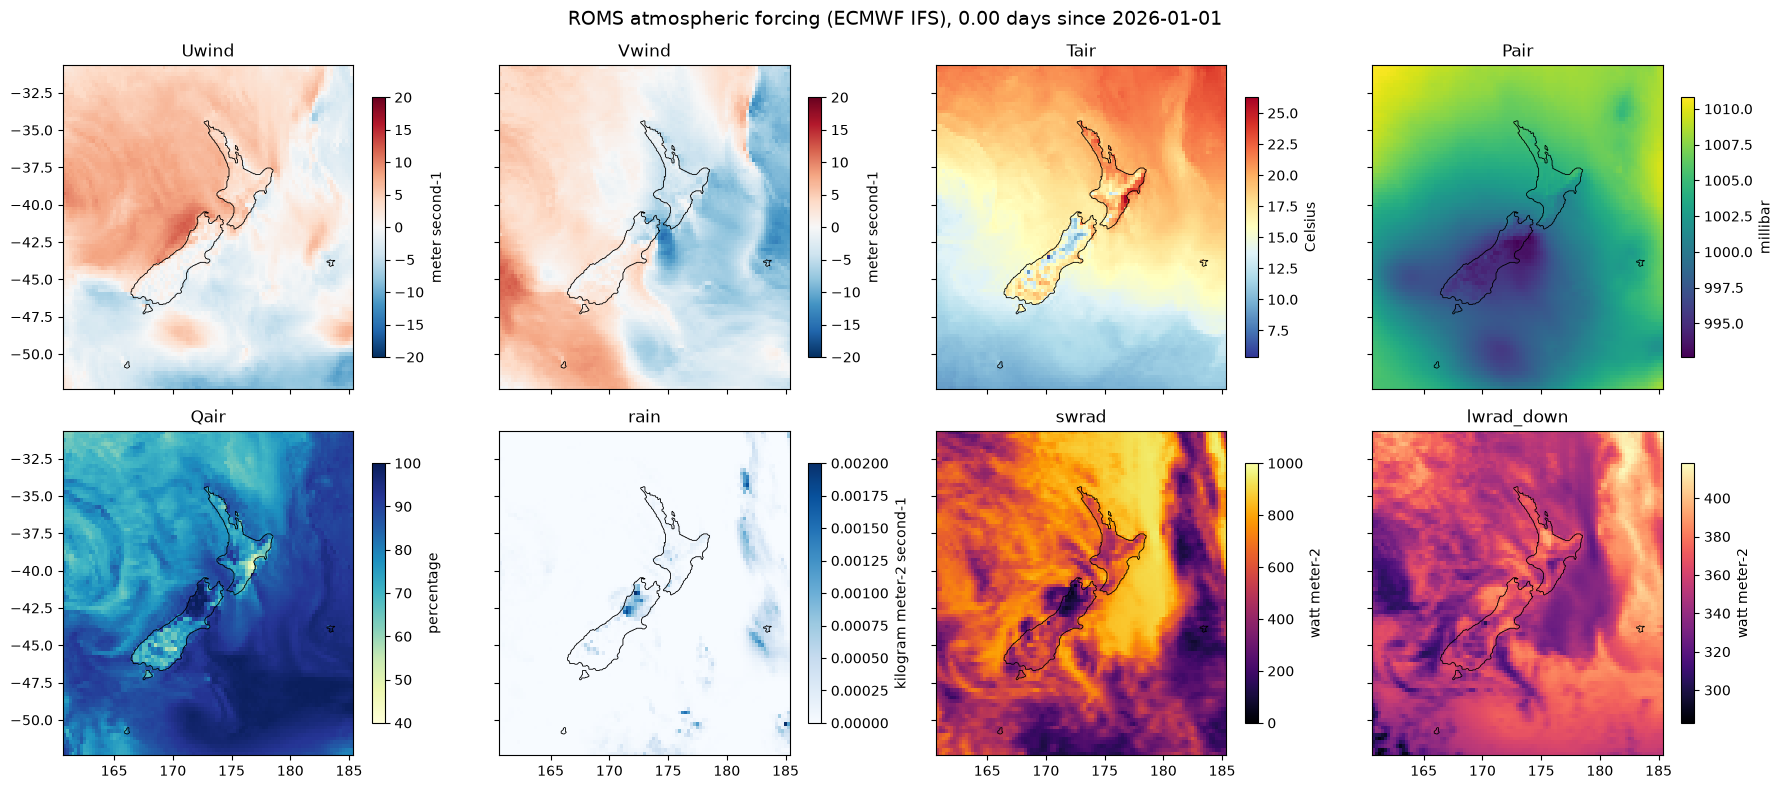

In [4]:
import xarray as xr
import numpy as np 
import matplotlib.pyplot as plt 

FRC  = "/home/nn411/Projects/OceanAtm/Moana-2.0/Data/moana_frc_ifs_2026-01-01_90D.nc"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"
FIGS = "/home/nn411/Projects/OceanAtm/Moana-2.0/Figures"
T    = 0.0     # days since 2026-01-01 -> 2026-01-01 00:00 UTC (1 pm in NZ, so the sun is up)

f = xr.open_dataset(FRC, decode_times=False)
g = xr.open_dataset(GRID)
it = int(np.argmin(abs(f.wind_time.values - T)))

panels = [("Uwind", "RdBu_r", (-20, 20)), ("Vwind", "RdBu_r", (-20, 20)),
          ("Tair", "RdYlBu_r", None),     ("Pair", "viridis", None),
          ("Qair", "YlGnBu", (40, 100)),  ("rain", "Blues", (0, 2e-3)),
          ("swrad", "inferno", (0, 1000)), ("lwrad_down", "magma", None)]

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
for ax, (name, cmap, lims) in zip(axes.flat, panels):
    da = f[name].isel(time=it)
    vmin, vmax = lims if lims else (float(da.min()), float(da.max()))
    pc = ax.pcolormesh(f.lon, f.lat, da, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto")
    ax.contour(g.lon_rho % 360, g.lat_rho, g.mask_rho, levels=[0.5], colors="k", linewidths=0.6)  # coastline
    fig.colorbar(pc, ax=ax, shrink=0.8, label=f[name].attrs["units"])
    ax.set_title(name)
fig.suptitle(f"ROMS atmospheric forcing (ECMWF IFS), {T:.2f} days since 2026-01-01", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIGS}/atm_forcing_maps.png", dpi=150)
plt.show()

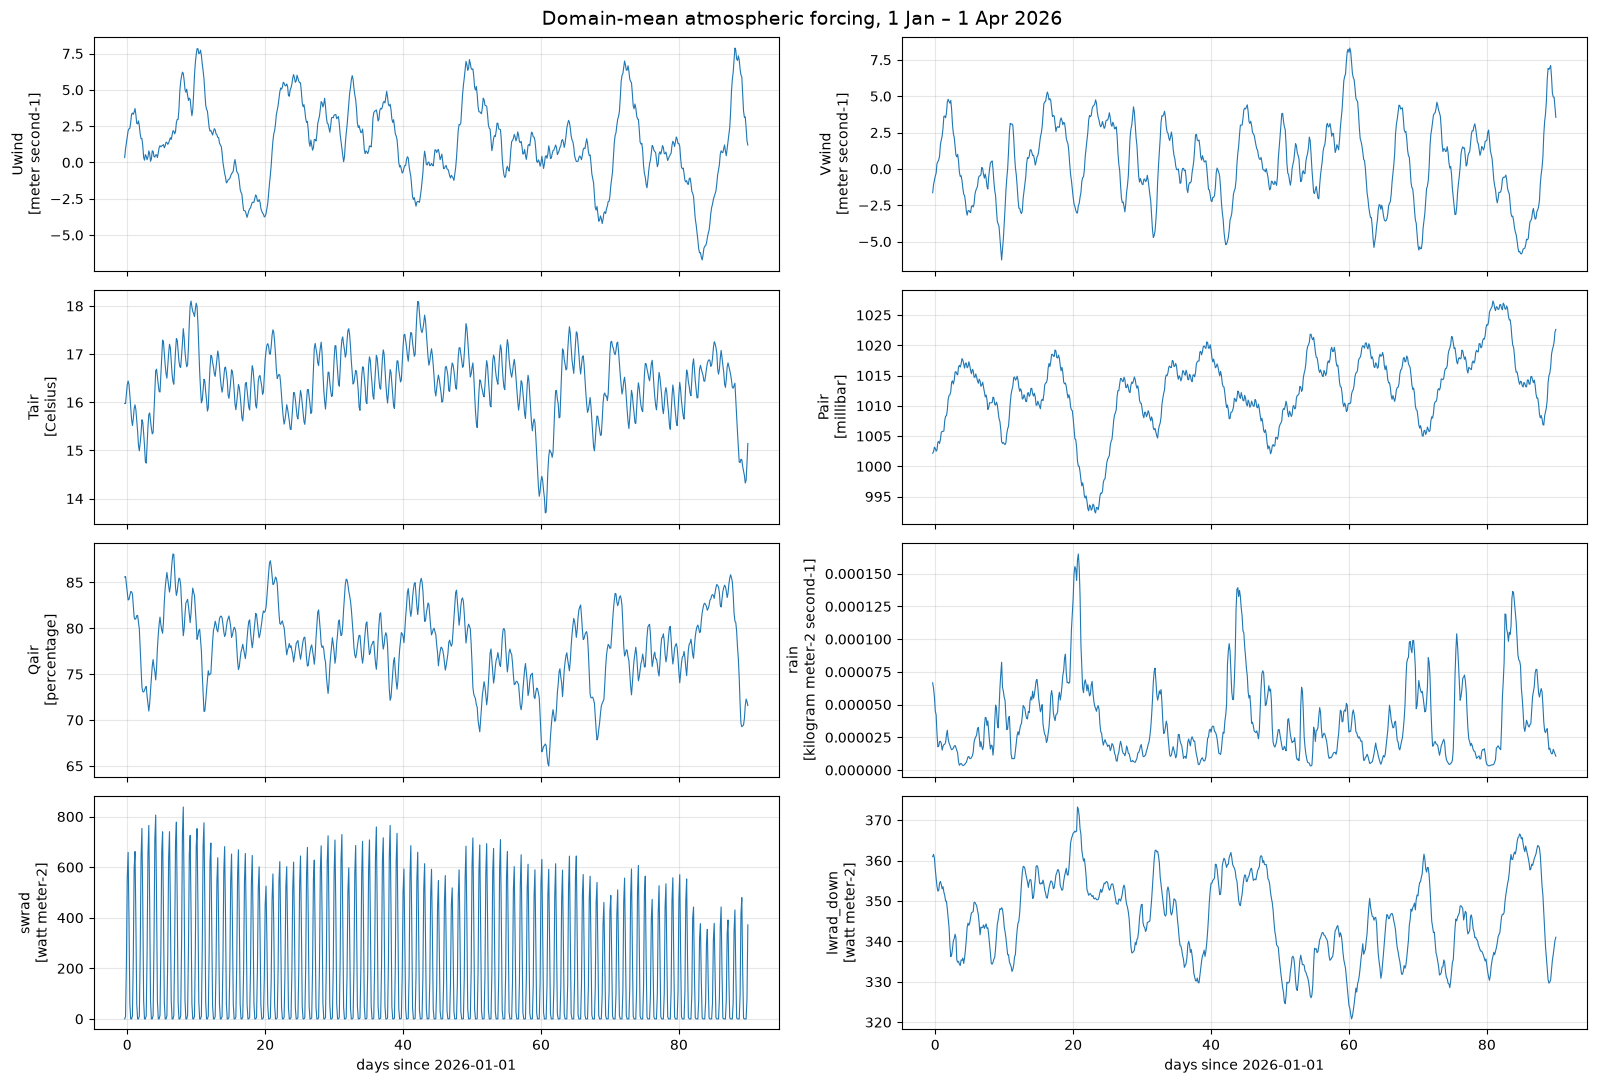

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True)
for ax, (name, _, _) in zip(axes.flat, panels):
    tname = f[name].attrs["time"]
    ax.plot(f[tname], f[name].mean(("lat", "lon")), lw=0.8)
    ax.set_ylabel(f"{name}\n[{f[name].attrs['units']}]")
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("days since 2026-01-01")
fig.suptitle("Domain-mean atmospheric forcing, 1 Jan – 1 Apr 2026", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIGS}/atm_forcing_timeseries.png", dpi=150)
plt.show()

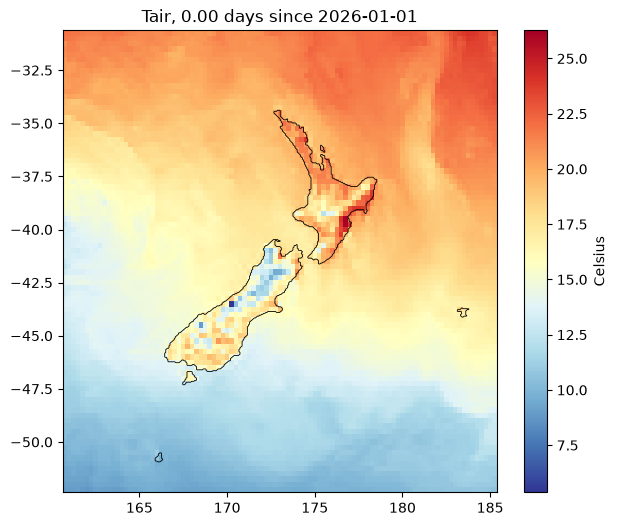

In [6]:

VAR  = "Tair"      # Uwind, Vwind, Tair, Pair, Qair, rain, swrad, lwrad_down
DAY  = 0.0         # days since 2026-01-01 (0.5 = 12:00 UTC on 1 Jan)
CMAP = "RdYlBu_r"
# ----------------------

f = xr.open_dataset("/home/nn411/Projects/OceanAtm/Moana-2.0/Data/moana_frc_ifs_2026-01-01_90D.nc", decode_times=False)
g = xr.open_dataset("/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc")

t = f[f[VAR].attrs["time"]]
it = int(np.argmin(abs(t.values - DAY)))

plt.figure(figsize=(7, 6))
plt.pcolormesh(f.lon, f.lat, f[VAR].isel(time=it), cmap=CMAP, shading="auto")
plt.colorbar(label=f[VAR].attrs["units"])
plt.contour(g.lon_rho % 360, g.lat_rho, g.mask_rho, levels=[0.5], colors="k", linewidths=0.6)
plt.title(f"{VAR}, {float(t[it]):.2f} days since 2026-01-01")
plt.show()

In [8]:
import pandas as pd 

f = xr.open_dataset("/home/nn411/Projects/OceanAtm/Moana-2.0/Data/moana_frc_ifs_2026-01-01_90D.nc", decode_times=False)
g = xr.open_dataset("/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc")
FIGS = "/home/nn411/Projects/OceanAtm/Moana-2.0/Figures"

VARS = ["Uwind", "Vwind", "Tair", "Pair", "Qair", "rain", "swrad", "lwrad_down"]
LON, LAT = 175.0, -40.0                              # ocean point off the Wairarapa coast
dates = pd.Timestamp("2026-01-01") + pd.to_timedelta(f.wind_time.values, "D")
pt = f.sel(lon=LON, lat=LAT, method="nearest")
print(f"Point used: {float(pt.lon):.2f}°E, {float(pt.lat):.2f}°S")

Point used: 175.00°E, -40.00°S


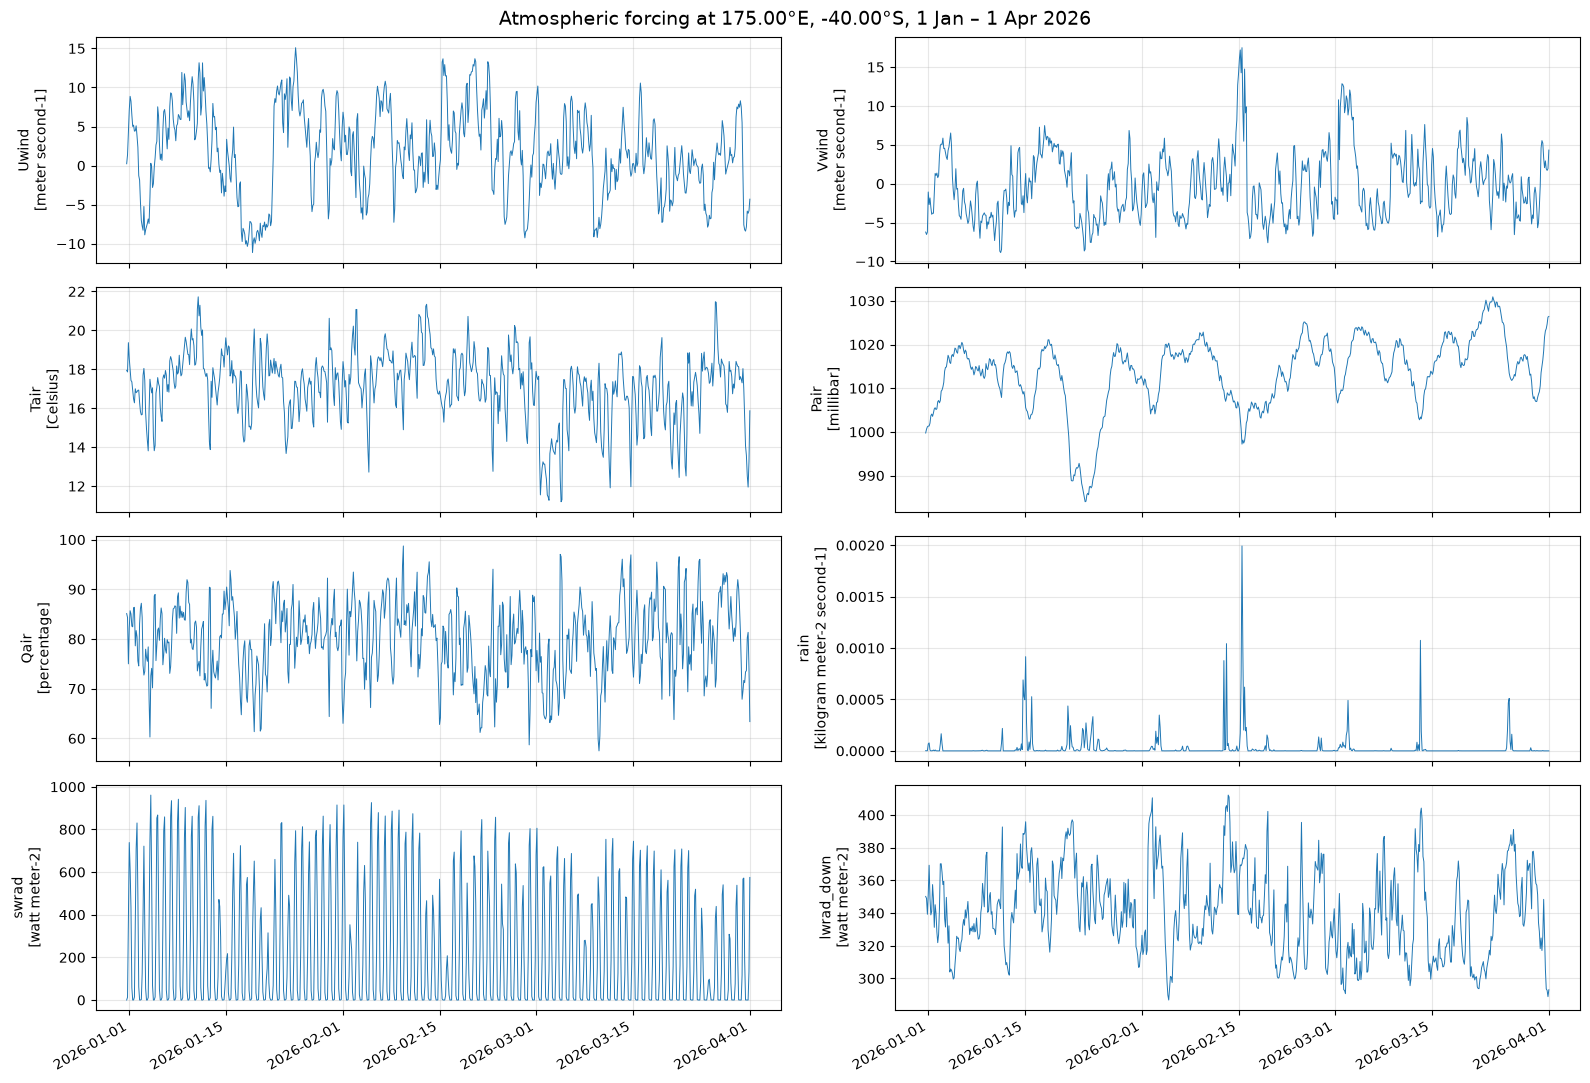

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True)
for ax, v in zip(axes.flat, VARS):
    ax.plot(dates, pt[v], lw=0.7)
    ax.set_ylabel(f"{v}\n[{f[v].attrs['units']}]")
    ax.grid(alpha=0.3)
fig.suptitle(f"Atmospheric forcing at {float(pt.lon):.2f}°E, {float(pt.lat):.2f}°S, 1 Jan – 1 Apr 2026", fontsize=14)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(f"{FIGS}/atm_forcing_point_timeseries.png", dpi=150)
plt.show()

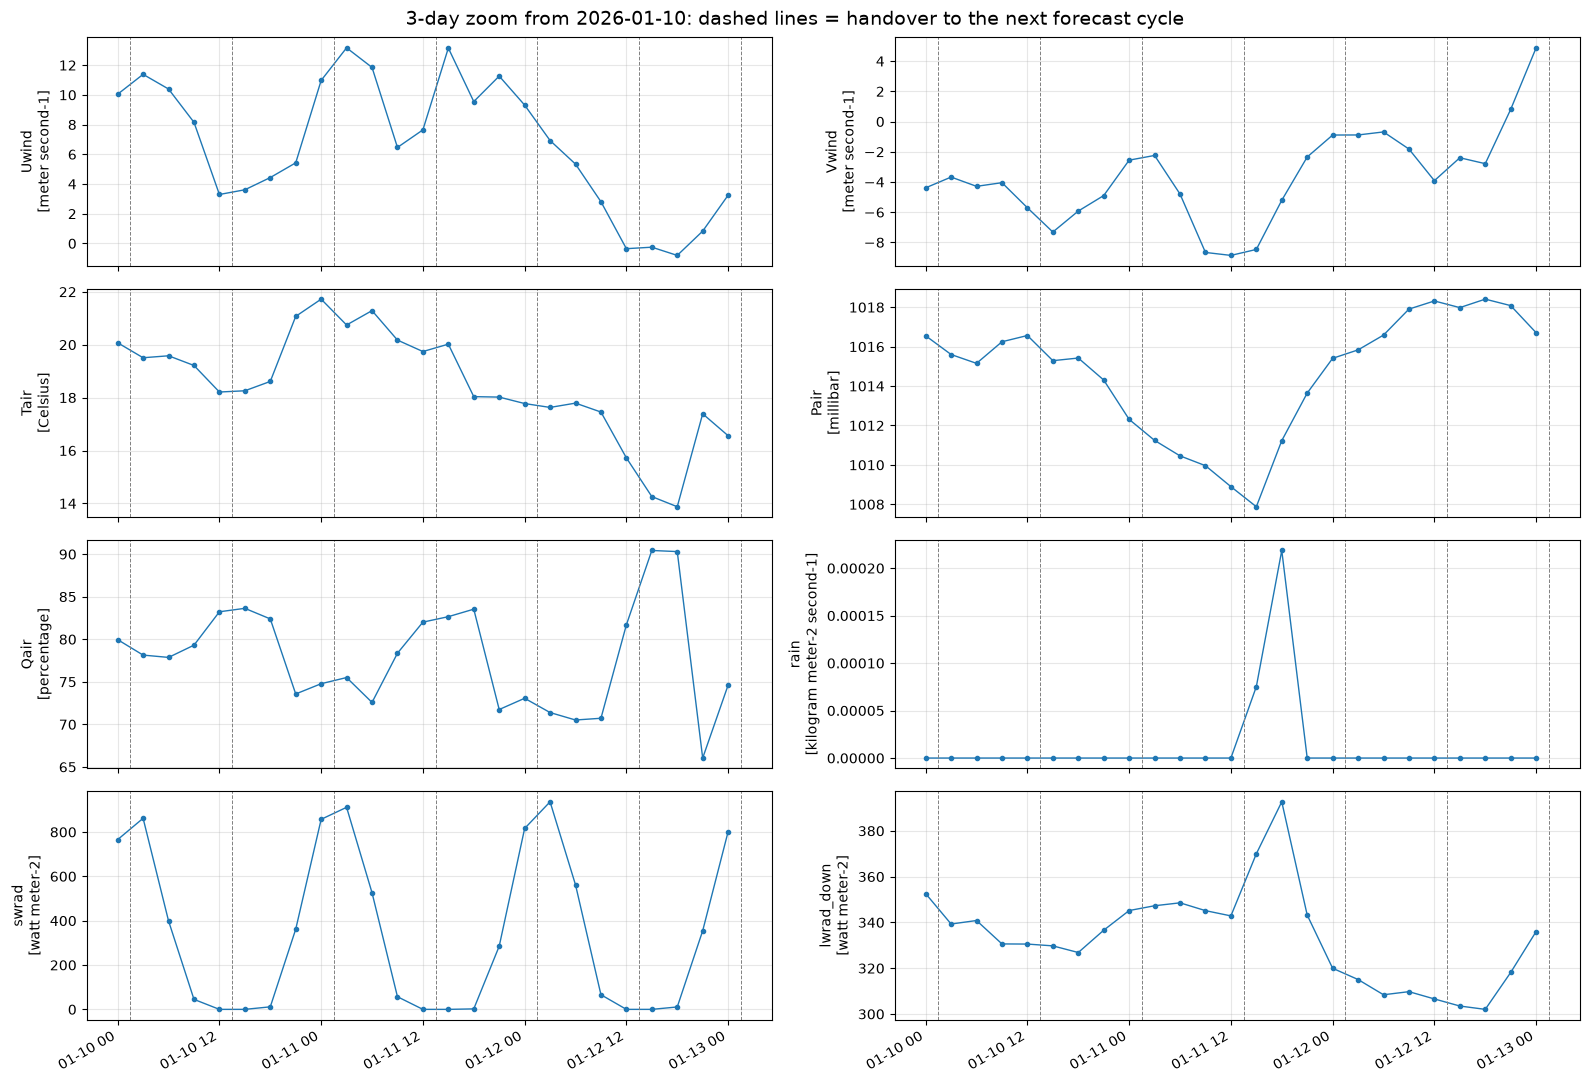

In [10]:
START, DAYS = "2026-01-10", 3                        # change to zoom elsewhere
t0 = pd.Timestamp(START); t1 = t0 + pd.Timedelta(days=DAYS)
sel = (dates >= t0) & (dates <= t1)
handovers = pd.date_range(t0, t1, freq="12h") + pd.Timedelta("1.5h")

fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True)
for ax, v in zip(axes.flat, VARS):
    ax.plot(dates[sel], pt[v].values[sel], "o-", ms=3, lw=1)
    for h in handovers:
        ax.axvline(h, color="gray", ls="--", lw=0.7)
    ax.set_ylabel(f"{v}\n[{f[v].attrs['units']}]")
    ax.grid(alpha=0.3)
fig.suptitle(f"{DAYS}-day zoom from {START}: dashed lines = handover to the next forecast cycle", fontsize=14)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(f"{FIGS}/atm_forcing_cycle_handovers.png", dpi=150)
plt.show()

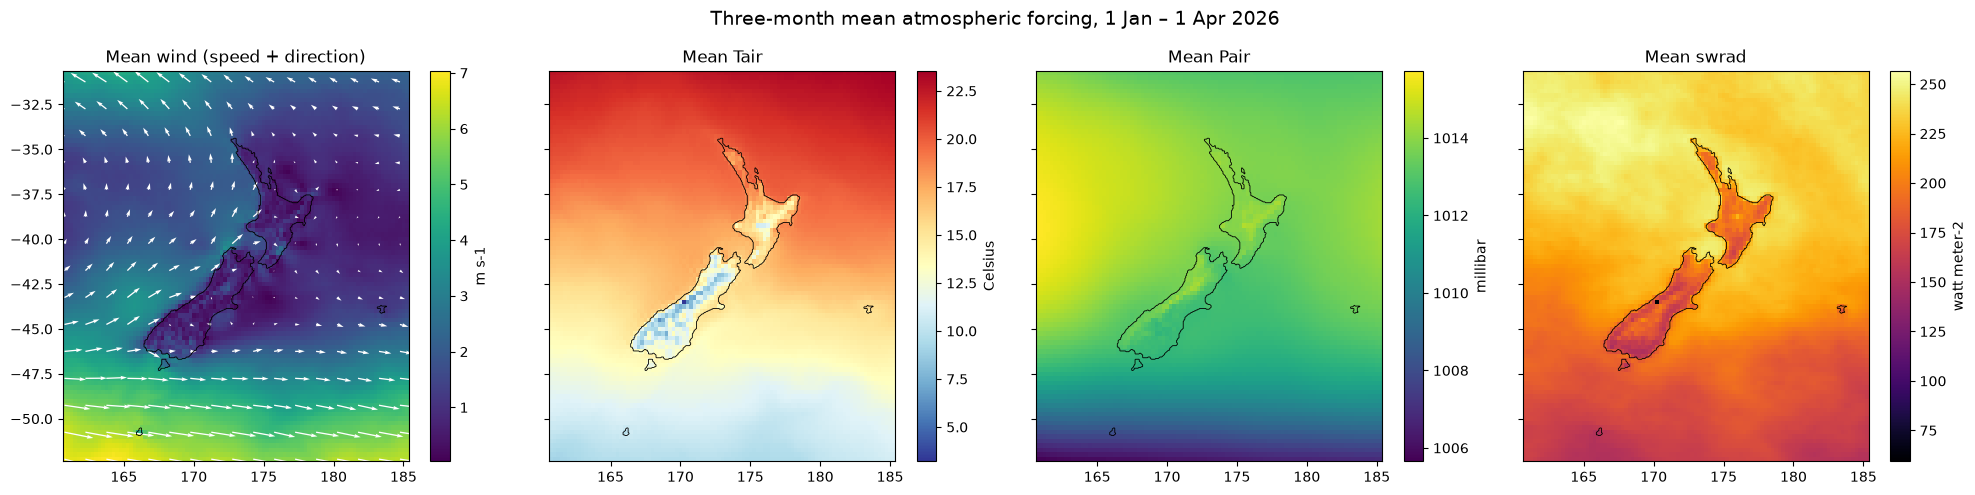

In [11]:
m = f.mean("time")
coast = dict(levels=[0.5], colors="k", linewidths=0.6)

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

speed = np.hypot(m.Uwind, m.Vwind)
pc = axes[0].pcolormesh(m.lon, m.lat, speed, cmap="viridis", shading="auto")
s = 6                                                # plot every 6th arrow
axes[0].quiver(m.lon[::s], m.lat[::s], m.Uwind[::s, ::s], m.Vwind[::s, ::s], color="w")
fig.colorbar(pc, ax=axes[0], label="m s-1")
axes[0].set_title("Mean wind (speed + direction)")

for ax, (v, cmap) in zip(axes[1:], [("Tair", "RdYlBu_r"), ("Pair", "viridis"), ("swrad", "inferno")]):
    pc = ax.pcolormesh(m.lon, m.lat, m[v], cmap=cmap, shading="auto")
    fig.colorbar(pc, ax=ax, label=f[v].attrs["units"])
    ax.set_title(f"Mean {v}")

for ax in axes:
    ax.contour(g.lon_rho % 360, g.lat_rho, g.mask_rho, **coast)
fig.suptitle("Three-month mean atmospheric forcing, 1 Jan – 1 Apr 2026", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIGS}/atm_forcing_mean_maps.png", dpi=150)
plt.show()